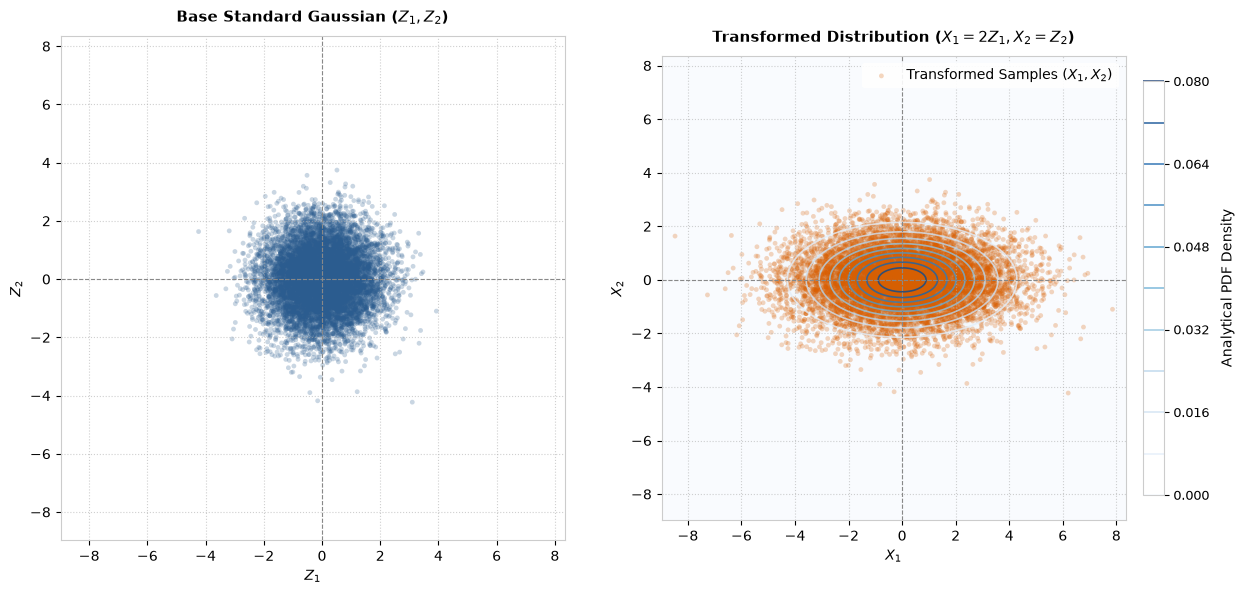

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Set a clean visual style
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

# 1. Define parameters for the base 2D Gaussian distribution (Z-space)
mean1, mean2 = 0, 0
sig1, sig2 = 1.0, 1.0

mean = [mean1, mean2]
cov = [[sig1, 0], [0, sig2]]

# 2. Generate samples in Z-space
num_samples = 10000
z_samples = np.random.multivariate_normal(mean, cov, num_samples)

# Separate z1 and z2 coordinates
z1 = z_samples[:, 0]
z2 = z_samples[:, 1]

# Forward transformation to X-space: x1 = 2*z1, x2 = z2
x1 = 2 * z1
x2 = z2

# --- Calculate shared axis limits dynamically ---
all_coords = np.concatenate([z1, z2, x1, x2])
lim_min = np.min(all_coords) - 0.5
lim_max = np.max(all_coords) + 0.5

# 3. Create the plots with a professional layout
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6))

# --- Plot 1: Original Standard Gaussian in Z-Space ---
ax1.scatter(z1, z2, alpha=0.25, color="#2b5c8f", edgecolor="none", s=12)
ax1.set_title("Base Standard Gaussian ($Z_1, Z_2$)", fontsize=11, fontweight="bold", pad=10)
ax1.set_xlabel("$Z_1$", fontsize=10)
ax1.set_ylabel("$Z_2$", fontsize=10)
ax1.grid(True, linestyle=":", alpha=0.6, color="#b0b0b0")
ax1.axhline(0, color="#888888", linewidth=0.8, linestyle="--")
ax1.axvline(0, color="#888888", linewidth=0.8, linestyle="--")
ax1.set_xlim(lim_min, lim_max)
ax1.set_ylim(lim_min, lim_max)
ax1.set_aspect("equal")

# --- Plot 2: Transformed Distribution in X-Space with Analytical Contours ---
grid_size = 300
X1_grid, X2_grid = np.meshgrid(
    np.linspace(lim_min, lim_max, grid_size),
    np.linspace(lim_min, lim_max, grid_size),
)

# Calculate analytical PDF values in X-space using change of variables:
# p(x1, x2) = p_z(x1/2, x2) * |det(J)^(-1)| = [1 / (4 * pi)] * exp(- (((x1/2))^2 + x2^2) / 2)
pdf_x = (1 / (4 * np.pi)) * np.exp(- (((X1_grid / 2) ** 2) + X2_grid**2) / 2)

# Use your preferred clean sequential colormap ('Blues')
cmap_choice = "Blues"

# Add smooth filled contours for the density heatmap
contourf = ax2.contourf(
    X1_grid,
    X2_grid,
    pdf_x,
    levels=15,
    cmap=cmap_choice,
    alpha=0.4,
    antialiased=True
)

# Overlay crisp contour lines
contour = ax2.contour(
    X1_grid,
    X2_grid,
    pdf_x,
    levels=10,
    cmap=cmap_choice,
    alpha=0.8,
    linewidths=1.2
)

# Overlay the transformed samples using your warm accent color
ax2.scatter(
    x1,
    x2,
    alpha=0.25,
    color="#d95f02",  # Warm accent color contrasting with blue
    edgecolor="none",
    s=12,
    label="Transformed Samples ($X_1, X_2$)",
)

ax2.set_title("Transformed Distribution ($X_1 = 2Z_1, X_2 = Z_2$)", fontsize=11, fontweight="bold", pad=10)
ax2.set_xlabel("$X_1$", fontsize=10)
ax2.set_ylabel("$X_2$", fontsize=10)
ax2.grid(True, linestyle=":", alpha=0.6, color="#b0b0b0")
ax2.axhline(0, color="#888888", linewidth=0.8, linestyle="--")
ax2.axvline(0, color="#888888", linewidth=0.8, linestyle="--")

# Apply shared limits and equal aspect ratio
ax2.set_xlim(lim_min, lim_max)
ax2.set_ylim(lim_min, lim_max)
ax2.set_aspect("equal")

# Refine colorbar placement and formatting
cbar = fig.colorbar(contour, ax=ax2, shrink=0.82, pad=0.03)
cbar.set_label("Analytical PDF Density", fontsize=10, labelpad=8)
cbar.ax.tick_params(labelsize=9)

# Legend formatting
ax2.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="none", framealpha=0.9)

plt.tight_layout()
plt.show()